# Automatidata: NYC Taxi Data (Regression Modeling Stage)

Case study from the Google Advanced Data Analytics Professional Certificate (Course 4: Regression Analysis). Building a multiple linear regression model to predict taxi fares for the NYC Taxi and Limousine Commission.

# **Build a multiple linear regression model**

## Plan

### Imports and data loading

In [1]:
# Imports
# Packages for numerics + dataframes
import pandas as pd
import numpy as np

# Packages for visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Packages for OLS, MLR, confusion matrix
import sklearn.metrics as metrics
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [2]:
# Load dataset into dataframe 
df0=pd.read_csv("2017_Yellow_Taxi_Trip_Data.csv") 

## Analyze

What are some purposes of EDA before constructing a multiple linear regression model?

To understand your data and check for missing values that ruinthe accuracy of the model, or duplicates and outliers. 

### Data exploration

In [3]:
# Start with `.shape` and `.info()`
print("shape: ", df0.shape)
print(df0.info())


shape:  (22699, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             22699 non-null  int64  
 1   VendorID               22699 non-null  int64  
 2   tpep_pickup_datetime   22699 non-null  object 
 3   tpep_dropoff_datetime  22699 non-null  object 
 4   passenger_count        22699 non-null  int64  
 5   trip_distance          22699 non-null  float64
 6   RatecodeID             22699 non-null  int64  
 7   store_and_fwd_flag     22699 non-null  object 
 8   PULocationID           22699 non-null  int64  
 9   DOLocationID           22699 non-null  int64  
 10  payment_type           22699 non-null  int64  
 11  fare_amount            22699 non-null  float64
 12  extra                  22699 non-null  float64
 13  mta_tax                22699 non-null  float64
 14  tip_amount             22699 non-n

In [4]:
# Check for missing data and duplicates using .isna() and .drop_duplicates()
print("duplicated: ",df0.duplicated().sum())
print(df0.isna().sum())

duplicated:  0
Unnamed: 0               0
VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
RatecodeID               0
store_and_fwd_flag       0
PULocationID             0
DOLocationID             0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
dtype: int64


In [5]:
# Use .describe()
df0.describe()


,Unnamed: 0,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount
count,2.269900e+04,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000,22699.000000
mean,5.675849e+07,1.556236,1.642319,2.913313,1.043394,162.412353,161.527997,1.336887,13.026629,0.333275,0.497445,1.835781,0.312542,0.299551,16.310502
std,3.274493e+07,0.496838,1.285231,3.653171,0.708391,66.633373,70.139691,0.496211,13.243791,0.463097,0.039465,2.800626,1.399212,0.015673,16.097295
min,1.212700e+04,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,-120.000000,-1.000000,-0.500000,0.000000,0.000000,-0.300000,-120.300000
25%,2.852056e+07,1.000000,1.000000,0.990000,1.000000,114.000000,112.000000,1.000000,6.500000,0.000000,0.500000,0.000000,0.000000,0.300000,8.750000
50%,5.673150e+07,2.000000,1.000000,1.610000,1.000000,162.000000,162.000000,1.000000,9.500000,0.000000,0.500000,1.350000,0.000000,0.300000,11.800000
75%,8.537452e+07,2.000000,2.000000,3.060000,1.000000,233.000000,233.000000,2.000000,14.500000,0.500000,0.500000,2.450000,0.000000,0.300000,17.800000
max,1.134863e+08,2.000000,6.000000,33.960000,99.000000,265.000000,265.000000,4.000000,999.990000,4.500000,0.500000,200.000000,19.100000,0.300000,1200.290000


### Convert pickup & dropoff columns to datetime

In [6]:
# Check the format of the data
df0.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             22699 non-null  int64  
 1   VendorID               22699 non-null  int64  
 2   tpep_pickup_datetime   22699 non-null  object 
 3   tpep_dropoff_datetime  22699 non-null  object 
 4   passenger_count        22699 non-null  int64  
 5   trip_distance          22699 non-null  float64
 6   RatecodeID             22699 non-null  int64  
 7   store_and_fwd_flag     22699 non-null  object 
 8   PULocationID           22699 non-null  int64  
 9   DOLocationID           22699 non-null  int64  
 10  payment_type           22699 non-null  int64  
 11  fare_amount            22699 non-null  float64
 12  extra                  22699 non-null  float64
 13  mta_tax                22699 non-null  float64
 14  tip_amount             22699 non-null  float64
 15  to

In [7]:
# Convert datetime columns to datetime
df0["tpep_pickup_datetime"] = pd.to_datetime(df0["tpep_pickup_datetime"])
df0["tpep_dropoff_datetime"] = pd.to_datetime(df0["tpep_dropoff_datetime"])

### Create duration column

In [8]:
# Create `duration` column
df0["duration"] = (df0["tpep_dropoff_datetime"] - df0["tpep_pickup_datetime"]).dt.total_seconds() / 60

### Outliers

In [9]:
df0.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Unnamed: 0             22699 non-null  int64         
 1   VendorID               22699 non-null  int64         
 2   tpep_pickup_datetime   22699 non-null  datetime64[ns]
 3   tpep_dropoff_datetime  22699 non-null  datetime64[ns]
 4   passenger_count        22699 non-null  int64         
 5   trip_distance          22699 non-null  float64       
 6   RatecodeID             22699 non-null  int64         
 7   store_and_fwd_flag     22699 non-null  object        
 8   PULocationID           22699 non-null  int64         
 9   DOLocationID           22699 non-null  int64         
 10  payment_type           22699 non-null  int64         
 11  fare_amount            22699 non-null  float64       
 12  extra                  22699 non-null  float64       
 13  m

Many of the features will not be used to fit the model, so the most important columns to check for outliers are likely to be:
* `trip_distance`
* `fare_amount`
* `duration`

### Box plots

Text(0.5, 1.0, 'Duration')

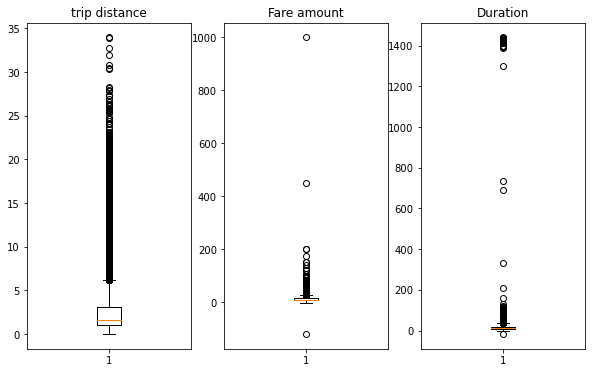

In [10]:
plt.figure(figsize=(10,6))
plt.subplot(1,3,1)
plt.boxplot(df0["trip_distance"]);
plt.title("trip distance")

plt.subplot(1,3,2)
plt.boxplot(df0["fare_amount"]);
plt.title("Fare amount")

plt.subplot(1,3,3)
plt.boxplot(df0["duration"]);
plt.title("Duration")



**Questions:** 
1. Which variable(s) contains outliers? 

2. Are the values in the `trip_distance` column unbelievable?

3. What about the lower end? Do distances, fares, and durations of 0 (or negative values) make sense?

All of the variables has outliers,  Not really something about it. No it doesn't make sense fare amount has a negtaive values and the diuration has zero and distance i think its on zero.

### Imputations

#### `trip_distance` outliers

Trip distances of 0 appear in the summary statistics. Are these erroneous data, or very short trips that get rounded down?

In [11]:
# Are trip distances of 0 bad data or very short trips rounded down?
df0["trip_distance"].drop_duplicates().sort_values().head(10)

128      0.00
2985     0.01
323      0.02
3158     0.03
1510     0.04
10146    0.05
4423     0.06
922      0.07
4623     0.08
22035    0.09
Name: trip_distance, dtype: float64

The distances are captured with a high degree of precision. However, it might be possible for trips to have distances of zero if a passenger summoned a taxi and then changed their mind. Besides, are there enough zero values in the data to pose a problem?

In [12]:
df0[df0["trip_distance"] == 0].shape[0]

148

#### `fare_amount` outliers

In [13]:
df0["fare_amount"].describe()

count    22699.000000
mean        13.026629
std         13.243791
min       -120.000000
25%          6.500000
50%          9.500000
75%         14.500000
max        999.990000
Name: fare_amount, dtype: float64

In [14]:
# Impute values less than $0 with 0
df0["fare_amount"] = df0["fare_amount"].apply(lambda x: 0 if x < 0 else x)
# we could also use the clip(lower=0)

High outliers are imputed with `Q3 + (6 * IQR)`.

In [15]:
def outlierImpute(df, col):
    # Reassign minimum to zero
    df[col] = df[col].clip(lower=0)
        
    # Calculate upper threshold
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    threshold = q3 + (6 * iqr)
    
    # Reassign values > threshold to threshold
    df[col] = df[col].clip(upper=threshold)
    

In [16]:
outlierImpute(df0,"fare_amount")

#### `duration` outliers

In [17]:
# Call .describe() for duration outliers
df0["duration"].describe()

count    22699.000000
mean        17.013777
std         61.996482
min        -16.983333
25%          6.650000
50%         11.183333
75%         18.383333
max       1439.550000
Name: duration, dtype: float64

The `duration` column has problematic values at both the lower and upper extremities.

* **Low values:** There should be no values that represent negative time, so negative durations are imputed with `0`.

* **High values:** High values are imputed the same way as the high-end outliers for fares: `Q3 + (6 * IQR)`.

In [18]:
# Impute a 0 for any negative values
df0["duration"] = df0["duration"].clip(lower=0)

In [19]:
# Impute the high outliers
outlierImpute(df0, "duration")

### Feature engineering

#### Create `mean_distance` column

When deployed, the model will not know the duration of a trip until after the trip occurs, so it cannot be trained on that feature. However, the statistics of trips that *are* known can be used to generalize about ones that are not.

`mean_distance` captures the mean distance for each group of trips that share pickup and dropoff points. Notice that C -> D is not the same as D -> C: all trips that share a unique pair of start and end points get grouped and averaged.

A helper column called `pickup_dropoff` holds the unique combination of pickup and dropoff location IDs for each row. The IDs are converted to strings and joined with a space, so that, for example, a trip with pickup/dropoff points of 12 & 151 gets encoded differently than a trip with points 121 & 51.

In [20]:
# Create `pickup_dropoff` column
df0["pickup_dropoff"] = df0["PULocationID"].astype(str) + " " + df0["DOLocationID"].astype(str)
df0["pickup_dropoff"]

0        100 231
1         186 43
2        262 236
3         188 97
4          4 112
          ...   
22694     48 186
22695    132 164
22696    107 234
22697     68 144
22698    239 236
Name: pickup_dropoff, Length: 22699, dtype: object

In [21]:
grouped = df0.groupby("pickup_dropoff")["trip_distance"].mean()
grouped

pickup_dropoff
1 1         2.433333
10 148     15.700000
100 1      16.890000
100 100     0.253333
100 107     1.180000
             ...    
97 65       0.500000
97 66       1.400000
97 80       3.840000
97 90       4.420000
97 97       1.006667
Name: trip_distance, Length: 4172, dtype: float64

In [22]:
# 1. Convert `grouped` to a dictionary
# 2. Reassign to only contain the inner dictionary
grouped_dict = grouped.to_dict() 

In [23]:
# 1. Create a mean_distance column that is a copy of the pickup_dropoff helper column
# 2. Map `grouped_dict` to the `mean_distance` column
df0["mean_distance"] = df0["pickup_dropoff"].map(grouped_dict)

# Confirm that it worked
df0["mean_distance"]


0         3.521667
1         3.108889
2         0.881429
3         3.700000
4         4.435000
           ...    
22694     1.098214
22695    18.757500
22696     0.684242
22697     2.077500
22698     1.476970
Name: mean_distance, Length: 22699, dtype: float64

#### Create `mean_duration` column

In [24]:
grouped2 = df0.groupby("pickup_dropoff")["duration"].mean()

# Create a dictionary where keys are unique pickup_dropoffs and values are
# mean trip duration for all trips with those pickup_dropoff combos
grouped2_dict = grouped2.to_dict()
df0["mean_duration"] = df0["pickup_dropoff"].map(grouped2_dict)

# Confirm that it worked
df0["mean_duration"]

0        22.847222
1        24.470370
2         7.250000
3        30.250000
4        14.616667
           ...    
22694     8.594643
22695    59.560417
22696     6.609091
22697    16.650000
22698     9.405556
Name: mean_duration, Length: 22699, dtype: float64

#### Create `day` and `month` columns

In [25]:
# Create 'day' col
df0["day"] = df0["tpep_pickup_datetime"].dt.day_name()
# Create 'month' col
df0["month"] = df0["tpep_pickup_datetime"].dt.month_name()

#### Create `rush_hour` column

Rush hour is defined as:
* Any weekday (not Saturday or Sunday) AND
* Either from 06:00&ndash;10:00 or from 16:00&ndash;20:00

`rush_hour` is a binary column that contains a 1 if the ride was during rush hour and a 0 if it was not.

In [26]:
# Create 'rush_hour' col
df0["rush_hour"] = df0["tpep_pickup_datetime"].dt.hour
# If day is Saturday or Sunday, impute 0 in `rush_hour` column

In [27]:
def rush_hourizer(df):
    if 6 <= df["rush_hour"] < 10:
        result = 1
    elif 16 <= df["rush_hour"] < 20:
        result = 1
    else:
        result = 0
    if df["day"] in ("Saturday", "Sunday"):
        result = 0
    return result

In [28]:
# Apply the `rush_hourizer()` function to the new column
df0["rush_hour"] = df0.apply(rush_hourizer, axis=1)

### Scatter plot

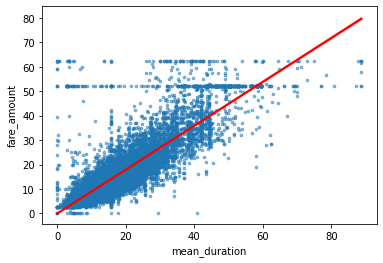

In [29]:
# Create a scatterplot to visualize the relationship between variables of interest
# sns.scatterplot(data=df0, x="mean_duration", y="fare_amount")????
sns.regplot(data=df0,x="mean_duration", y="fare_amount", scatter_kws={"alpha": 0.5, "s": 7}, line_kws={"color": "red"} )


The `mean_duration` variable correlates with the target variable. But there are two horizontal lines around fare amounts of 52 dollars and 63 dollars. 62 dollars and 50 cents is the maximum that was imputed for outliers, so all former outliers now have fare amounts of \$62.50. What is the other line?

In [30]:
df0[df0["fare_amount"] > 50]["fare_amount"].value_counts()

52.0    514
62.5     84
59.0      9
50.5      9
57.5      8
51.0      7
60.0      6
55.0      6
51.5      6
53.0      4
52.5      4
61.0      3
62.0      3
55.5      3
56.0      3
56.5      3
58.5      2
59.5      2
61.5      2
57.0      2
54.0      2
58.0      1
54.7      1
54.5      1
Name: fare_amount, dtype: int64

In [31]:
# Set pandas to display all columns
df0[df0["fare_amount"] == 52].head(30)

,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,...,tolls_amount,improvement_surcharge,total_amount,duration,pickup_dropoff,mean_distance,mean_duration,day,month,rush_hour
11,18600059,2,2017-03-05 19:15:30,2017-03-05 19:52:18,2,18.90,2,N,236,132,...,5.54,0.3,72.92,36.800000,236 132,19.211667,40.500000,Sunday,March,0
110,47959795,1,2017-06-03 14:24:57,2017-06-03 15:31:48,1,18.00,2,N,132,163,...,0.00,0.3,52.80,66.850000,132 163,19.229000,52.941667,Saturday,June,0
161,95729204,2,2017-11-11 20:16:16,2017-11-11 20:17:14,1,0.23,2,N,132,132,...,0.00,0.3,52.80,0.966667,132 132,2.255862,3.021839,Saturday,November,0
247,103404868,2,2017-12-06 23:37:08,2017-12-07 00:06:19,1,18.93,2,N,132,79,...,0.00,0.3,52.80,29.183333,132 79,19.431667,47.275000,Wednesday,December,0
379,80479432,2,2017-09-24 23:45:45,2017-09-25 00:15:14,1,17.99,2,N,132,234,...,5.76,0.3,73.20,29.483333,132 234,17.654000,49.833333,Sunday,September,0
388,16226157,1,2017-02-28 18:30:05,2017-02-28 19:09:55,1,18.40,2,N,132,48,...,5.54,0.3,62.84,39.833333,132 48,18.761905,58.246032,Tuesday,February,1
406,55253442,2,2017-06-05 12:51:58,2017-06-05 13:07:35,1,4.73,2,N,228,88,...,5.76,0.3,58.56,15.616667,228 88,4.730000,15.616667,Monday,June,0
449,65900029,2,2017-08-03 22:47:14,2017-08-03 23:32:41,2,18.21,2,N,132,48,...,5.76,0.3,58.56,45.450000,132 48,18.761905,58.246032,Thursday,August,0
468,80904240,2,2017-09-26 13:48:26,2017-09-26 14:31:17,1,17.27,2,N,186,132,...,5.76,0.3,58.56,42.850000,186 132,17.096000,42.920000,Tuesday,September,0
520,33706214,2,2017-04-23 21:34:48,2017-04-23 22:46:23,6,18.34,2,N,132,148,...,0.00,0.3,57.80,71.583333,132 148,17.994286,46.340476,Sunday,April,0


**Question:** What do you notice about the first 30 trips?

They all have the same RatecodeID and the number 132 in LocationID in drop off and pick up. 

### Isolate modeling variables

Drop features that are redundant, irrelevant, or that will not be available in a deployed environment.

In [32]:
df0.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Unnamed: 0             22699 non-null  int64         
 1   VendorID               22699 non-null  int64         
 2   tpep_pickup_datetime   22699 non-null  datetime64[ns]
 3   tpep_dropoff_datetime  22699 non-null  datetime64[ns]
 4   passenger_count        22699 non-null  int64         
 5   trip_distance          22699 non-null  float64       
 6   RatecodeID             22699 non-null  int64         
 7   store_and_fwd_flag     22699 non-null  object        
 8   PULocationID           22699 non-null  int64         
 9   DOLocationID           22699 non-null  int64         
 10  payment_type           22699 non-null  int64         
 11  fare_amount            22699 non-null  float64       
 12  extra                  22699 non-null  float64       
 13  m

In [33]:
df = df0[["VendorID","fare_amount" ,
           "mean_distance", "mean_duration", "rush_hour"]].copy()

### Pair plot

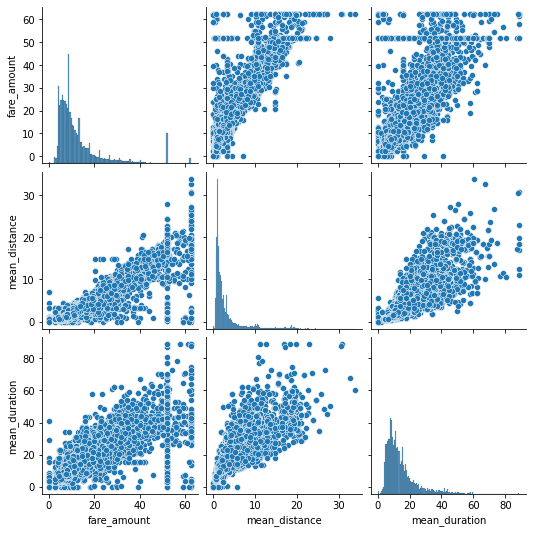

In [34]:
# Create a pairplot to visualize pairwise relationships between variables in the data
sns.pairplot(df[["fare_amount" ,"mean_distance", "mean_duration"]])

These variables all show linear correlation with each other.

### Identify correlations

In [35]:
# Correlation matrix to help determine most correlated variables
df.corr()

,VendorID,fare_amount,mean_distance,mean_duration,rush_hour
VendorID,1.000000,0.001045,0.004741,0.001876,-0.002874
fare_amount,0.001045,1.000000,0.910185,0.859105,-0.020075
mean_distance,0.004741,0.910185,1.000000,0.874864,-0.039725
mean_duration,0.001876,0.859105,0.874864,1.000000,-0.021583
rush_hour,-0.002874,-0.020075,-0.039725,-0.021583,1.000000


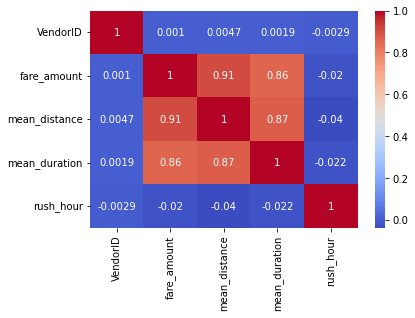

In [36]:
# Create correlation heatmap
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")

## Construct

### Split data into outcome variable and features

In [37]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22699 entries, 0 to 22698
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   VendorID       22699 non-null  int64  
 1   fare_amount    22699 non-null  float64
 2   mean_distance  22699 non-null  float64
 3   mean_duration  22699 non-null  float64
 4   rush_hour      22699 non-null  int64  
dtypes: float64(3), int64(2)
memory usage: 886.8 KB


In [62]:
# Remove the target column from the features
# X = df2.drop(columns='fare_amount')
# Set y variable
x = df.drop(columns=["fare_amount"])
y = df[["fare_amount"]]

# Display first few rows
x.head()

,VendorID,mean_distance,mean_duration,rush_hour
0,2,3.521667,22.847222,0
1,1,3.108889,24.470370,0
2,1,0.881429,7.250000,1
3,2,3.700000,30.250000,0
4,2,4.435000,14.616667,0


### Pre-process data

Dummy encode categorical variables

In [63]:
# Convert VendorID to string
x["VendorID"] = x["VendorID"].astype(str)

# Get dummies
x= pd.get_dummies(x,drop_first =True)
x.head()

,mean_distance,mean_duration,rush_hour,VendorID_2
0,3.521667,22.847222,0,1
1,3.108889,24.470370,0,0
2,0.881429,7.250000,1,0
3,3.700000,30.250000,0,1
4,4.435000,14.616667,0,1


### Split data into training and test sets

In [64]:
# Create training and testing sets
x_train , x_test , y_train, y_test = train_test_split(x,y, test_size= 0.2, random_state=0)


### Standardize the data

In [65]:
# Standardize the X variables
stscale = StandardScaler().fit(x_train)
x_train_scaled = stscale.transform(x_train)

### Fit the model

In [66]:
# Fit your model to the training data
model = LinearRegression().fit(x_train_scaled, y_train)

### Evaluate model

### Train data

Model performance is evaluated with the explained variance score (R^2), Mean Absolute Error, Mean Squared Error, and Root Mean Squared Error.

In [67]:
# Evaluate the model performance on the training data
lrscore = model.score(x_train_scaled, y_train)
y_pred = model.predict(x_train_scaled)

print(metrics.r2_score(y_train, y_pred))
print(metrics.mean_absolute_error(y_train, y_pred))
print(metrics.mean_squared_error(y_train, y_pred))
print(np.sqrt(metrics.mean_squared_error(y_train, y_pred)))
print(lrscore)

0.8398355624447613
2.186668467639144
17.890614965554306
4.229729892741888
0.8398355624447613


### Test data

The same metrics are calculated on the test data. The `X_test` data is scaled using the scaler that was fit to the training data. The scaler is not refit to the testing data, it is only used to transform it.

In [68]:
# Scale the X_test data
x_test_scaled = stscale.transform(x_test)

In [69]:
# Evaluate the model performance on the testing data
tlrscore = model.score(x_test_scaled, y_test)
y_predt = model.predict(x_test_scaled)

print(metrics.r2_score(y_test, y_predt))
print(metrics.mean_absolute_error(y_test, y_predt))
print(metrics.mean_squared_error(y_test, y_predt))
print(np.sqrt(metrics.mean_squared_error(y_test, y_predt)))
print(lrscore)


0.8682535390032758
2.133555705868846
14.326978878482738
3.785099586336235
0.8398355624447613


## Execute

### Results

`actual`, `predicted`, and `residual` for the testing set are stored as columns in a `results` dataframe.

In [70]:
# Create a `results` dataframe
result = pd.DataFrame(data={"actual": y_test["fare_amount"],"predicted": y_predt.ravel()})
result["residual"] = result["actual"] - result["predicted"]
result.head()



,actual,predicted,residual
5818,14.0,12.379699,1.620301
18134,28.0,16.338233,11.661767
4655,5.5,6.725850,-1.225850
7378,15.5,16.250415,-0.750415
13914,9.5,10.519144,-1.019144


### Visualize model results

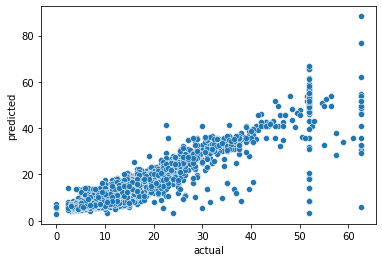

In [76]:
# Create a scatterplot to visualize `predicted` over `actual`
sns.scatterplot(data=result, x="actual", y="predicted")

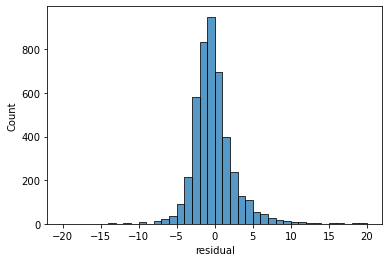

In [80]:
# Visualize the distribution of the `residuals`
sns.histplot(result["residual"], binrange=(-20, 20), binwidth = 1)



In [81]:
# Calculate residual mean
result["residual"].mean()

-0.016102923783802143

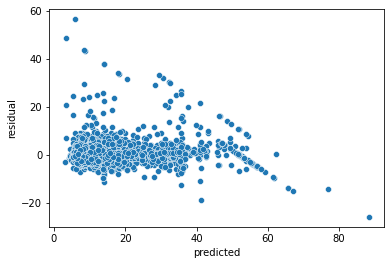

In [84]:
# Create a scatterplot of `residuals` over `predicted`
sns.scatterplot(data=result, x= "predicted", y= "residual")

### Coefficients

Which feature had the greatest effect on trip fare?

In [85]:
# Output the model's coefficients
model.coef_

array([[ 7.13369351,  2.81261699,  0.10960728, -0.04615418]])

What do these coefficients mean? How should they be interpreted?

The coefficients show how much the predicted fare changes for a one std increase in each feature, holding the others constant. mean_distance is 7.13 has the largest effect, followed by mean_duration 2.81. rush_hour 0.11 and VendorID_2 -0.05 are near zero, so they have little influence on fare.

### Conclusion

1. What are the key takeaways from this notebook?

2. What results can be presented from this notebook?

Fare is affected mainly by trip distance, followed by duration, while rush hour and vendor have almost no effect. Distance and duration are highly correlated, and a linear regression fits the data well.

The model's test performance the R², MAE, RMSE, and the coefficients showing distance as the strongest predictor, and the actual vs predicted and residual plots showing how accurate the predictions are.